# Study 09 · 09 · E8 · Longer horizons: 8 and 12 weeks

**Question.** At 2–4 weeks, recent case counts already reflect the weather of the preceding weeks. Does the b3 climate block add skill when the horizon is longer than that delay?

**Design** (`protocolo_e8.md`, written after E1–E7, so the reading is descriptive):
- A **separate** two-output model for h = 8 and 12 weeks; the paper's (2, 3, 4) models are untouched.
- Same predictors at the origin as `historia_geo` and `b3_obs` (weather at lag 2, published by the origin close), same fixed hyperparameters, persistence offset, seeds and season blocks.
- Chronological Platt and count blend; probabilistic persistence and climatology refitted at h8 and h12.

Estimands as in E1: 18 seasons, pooled primary, equal-season mean, whole-season bootstrap.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import e8
import experiments as ex

FIG = STUDY / "figures"
RES = c.OUTPUT / "resultados"
cols = ["semilla", "bloque", "horizonte", "ubigeo", "semana_inicio", "origen_cierre", "casos_Dengue", "brote",
        "umbral_brote_casos", "persistencia", "mu_modelo", "conteo_publicado", "alpha_usada", "probabilidad_cruda", "probabilidad_calibrada"]
arms = {name: c.read_arm(name, columns=cols, folder=e8.OUT_DIR) for name in ("b3_obs_largo", "historia_geo_largo")}
inputs, _ = c.load_inputs(validate=False)
support = arms["b3_obs_largo"][arms["b3_obs_largo"].semilla.eq(17)][c.archive.OBSERVATIONS].reset_index(drop=True)
for name, frame in arms.items():
    pd.testing.assert_frame_equal(frame[frame.semilla.eq(17)][c.archive.OBSERVATIONS].reset_index(drop=True), support)
base = c.baselines(support, inputs["etiquetas"])
base.to_csv(c.OUTPUT / "baselines_largo.csv.gz", index=False)
print({n: len(f) for n, f in arms.items()}, "| rows per horizon:", support.groupby("horizonte").size().to_dict())

{'b3_obs_largo': 649350, 'historia_geo_largo': 649350} | rows per horizon: {8: 64935, 12: 64935}


## 1 · Leakage checks for every block, horizon, arm and seed

In [2]:
fits = pd.concat([pd.read_csv(e8.OUT_DIR / f"{n}_s{s}" / "ajustes.csv").assign(brazo=n) for n in arms for s in c.SEEDS])
for col in ("corte", "ultima_etiqueta_entrenamiento", "primer_origen_prueba", "corte_calibracion", "ultima_etiqueta_usada"):
    fits[col] = pd.to_datetime(fits[col])
calibrated = fits.ultima_etiqueta_usada.notna()
checks = {"training: last label <= cutoff": bool((fits.ultima_etiqueta_entrenamiento <= fits.corte).all()),
          "cutoff <= first test origin": bool((fits.corte <= fits.primer_origen_prueba).all()),
          "calibration: last label <= its cutoff": bool((fits.ultima_etiqueta_usada[calibrated] <= fits.corte_calibracion[calibrated]).all()),
          "blocks x horizons x arms x seeds": len(fits)}
assert all(v is True for k, v in checks.items() if k != "blocks x horizons x arms x seeds")
checks

{'training: last label <= cutoff': True,
 'cutoff <= first test origin': True,
 'calibration: last label <= its cutoff': True,
 'blocks x horizons x arms x seeds': 400}

## 2 · Climate effect and reference forecasts at 8 and 12 weeks (18 seasons)

In [3]:
s_b3, s_hg = ex.sse(arms["b3_obs_largo"]), ex.sse(arms["historia_geo_largo"])
s_pp, s_cl = ex.sse(base, "persistencia_prob"), ex.sse(base, "climatologia")
def table(a, b, name):
    t = ex.contrast(a, b)
    return t.assign(comparacion=name)[["comparacion", *t.columns]]
main = pd.concat([table(s_b3, s_hg, "b3 vs history+geography (climate effect)"),
                  table(s_b3, s_pp, "b3 vs probabilistic persistence"),
                  table(s_hg, s_pp, "history+geography vs probabilistic persistence"),
                  table(s_b3, s_cl, "b3 vs climatology"), table(s_hg, s_cl, "history+geography vs climatology"),
                  table(s_pp, s_cl, "probabilistic persistence vs climatology")])
main.to_csv(RES / "e8_principal.csv", index=False)
main.round(4)

,comparacion,horizonte,temporadas,brier_a,brier_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,ic95_igual_peso,temporadas_a_mejor
0,b3 vs history+geography (climate effect),8,18,0.0465,0.0466,-0.0524,"(-4.71, 3.22)",0.1638,"(-4.95, 4.92)",8
1,b3 vs history+geography (climate effect),12,18,0.0530,0.0532,-0.5426,"(-5.06, 2.71)",-1.1602,"(-6.33, 3.56)",10
0,b3 vs probabilistic persistence,8,18,0.0465,0.0498,-6.5842,"(-15.53, 10.0)",33.5451,"(5.05, 67.28)",8
1,b3 vs probabilistic persistence,12,18,0.0530,0.0576,-8.1041,"(-17.28, 10.65)",34.9676,"(2.97, 72.98)",10
0,history+geography vs probabilistic persistence,8,18,0.0466,0.0498,-6.4382,"(-16.78, 12.91)",35.8584,"(5.27, 72.1)",7
1,history+geography vs probabilistic persistence,12,18,0.0532,0.0576,-7.5969,"(-18.08, 13.43)",39.3348,"(4.5, 80.89)",10
0,b3 vs climatology,8,18,0.0465,0.0697,-33.2177,"(-42.87, -17.17)",-19.8125,"(-33.43, -4.77)",15
1,b3 vs climatology,12,18,0.0530,0.0697,-24.0351,"(-33.26, -7.5)",-7.7966,"(-24.68, 12.09)",15
0,history+geography vs climatology,8,18,0.0466,0.0697,-33.1133,"(-43.49, -15.38)",-16.8057,"(-34.0, 3.04)",15
1,history+geography vs climatology,12,18,0.0532,0.0697,-23.6158,"(-33.77, -5.22)",-4.0484,"(-24.49, 20.77)",15


In [4]:
seasons = ex.by_season(s_b3, s_hg)
seasons.to_csv(RES / "e8_por_temporada.csv", index=False)
seasons.pivot(index="horizonte", columns="temporada", values="cambio_%").round(1)

temporada,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
horizonte,,,,,,,,,,,,,,,,,,
8,2.6,2.0,-17.1,-0.8,-1.6,-2.2,-5.7,5.8,2.1,-29.5,25.9,0.8,-1.0,5.7,4.8,-0.6,5.1,6.7
12,-0.3,1.1,-17.4,-0.1,-0.6,-1.6,-4.2,3.1,-1.4,-30.7,20.5,-14.6,-0.6,6.6,3.4,0.5,8.6,6.8


## 3 · All horizons together (2–4 weeks from E1, 8–12 weeks from E8)

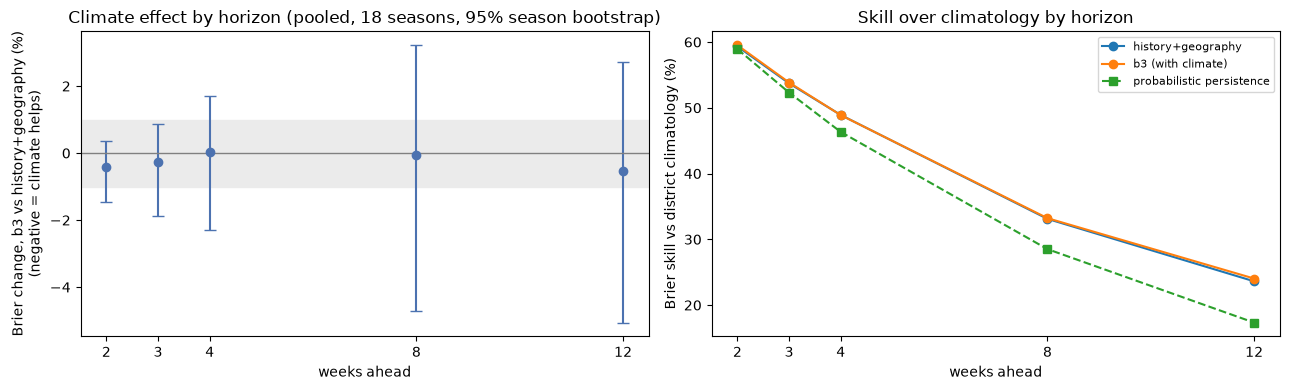

In [5]:
short = pd.read_csv(RES / "e1_principal_18_temporadas.csv")
both = pd.concat([short, main.assign(ic95_agrupado=main.ic95_agrupado.astype(str), ic95_igual_peso=main.ic95_igual_peso.astype(str))])
import ast
def bounds(text):
    lo, hi = ast.literal_eval(text) if isinstance(text, str) else text
    return float(lo), float(hi)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d = both[both.comparacion.str.startswith("b3 vs history")].sort_values("horizonte")
lo_hi = np.array([bounds(x) for x in d.ic95_agrupado])
axes[0].errorbar(d.horizonte, d["cambio_agrupado_%"], yerr=[d["cambio_agrupado_%"] - lo_hi[:, 0], lo_hi[:, 1] - d["cambio_agrupado_%"]],
                 fmt="o", capsize=4, color="#4C72B0")
axes[0].axhline(0, color="0.5", lw=1)
axes[0].axhspan(-1, 1, color="0.92", zorder=0)
axes[0].set_xticks([2, 3, 4, 8, 12])
axes[0].set_xlabel("weeks ahead")
axes[0].set_ylabel("Brier change, b3 vs history+geography (%)\n(negative = climate helps)")
axes[0].set_title("Climate effect by horizon (pooled, 18 seasons, 95% season bootstrap)")
for name, label in (("history+geography vs climatology", "history+geography"), ("b3 vs climatology", "b3 (with climate)")):
    e = both[both.comparacion.eq(name)].sort_values("horizonte")
    axes[1].plot(e.horizonte, -e["cambio_agrupado_%"], marker="o", label=label)
base_short = pd.read_csv(c.OUTPUT / "baselines.csv.gz", dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])
pp_short = ex.contrast(ex.sse(base_short, "persistencia_prob"), ex.sse(base_short, "climatologia"))
pp_all = pd.concat([pp_short, main[main.comparacion.eq("probabilistic persistence vs climatology")]]).sort_values("horizonte")
pp_all.assign(comparacion="probabilistic persistence vs climatology").to_csv(RES / "e8_persistencia_vs_climatologia_todos.csv", index=False)
axes[1].plot(pp_all.horizonte, -pp_all["cambio_agrupado_%"], marker="s", ls="--", label="probabilistic persistence")
axes[1].set_xticks([2, 3, 4, 8, 12])
axes[1].set_xlabel("weeks ahead")
axes[1].set_ylabel("Brier skill vs district climatology (%)")
axes[1].set_title("Skill over climatology by horizon")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e8_por_horizonte.png", dpi=160)

## 4 · Counts at 8 and 12 weeks

In [6]:
counts = pd.concat([ex.count_scores(f, name, with_wis=False) for name, f in arms.items()])
counts.to_csv(RES / "e8_conteos.csv", index=False)
summary = counts.groupby(["brazo", "horizonte", "temporada"]).median(numeric_only=True).groupby(["brazo", "horizonte"]).mean().drop(columns="semilla")
summary["mae_ratio_vs_persistence"] = summary.mae / summary.mae_persistencia
summary.round(3)

mae    rmse  mae_persistencia  mae_ratio_vs_persistence
brazo              horizonte                                                           
b3_obs_largo       8          3.604  17.796             4.560                     0.790
                   12         4.033  18.981             5.445                     0.741
historia_geo_largo 8          3.761  18.395             4.560                     0.825
                   12         4.519  20.956             5.445                     0.830